In [1]:
# Experiment 01 — Hadamard Gate: Superposition and Measurement

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

In [3]:
# Create a circuit with one Hadamard gate
qc = QuantumCircuit(1)
qc.h(0)

# Display the gate matrix
H = Operator(qc).data

print("Hadamard Gate Matrix:")
print(np.round(H, 4))

Hadamard Gate Matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]


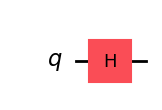

Statevector: [0.70710678+0.j 0.70710678+0.j]
Probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [4]:
# Create a one-qubit circuit
qc = QuantumCircuit(1)

# Apply the Hadamard gate
qc.h(0)

# Display the circuit
display(qc.draw("mpl"))

# Calculate the output state
state = Statevector.from_instruction(qc)

print("Statevector:", state.data)
print("Probabilities:", state.probabilities_dict())

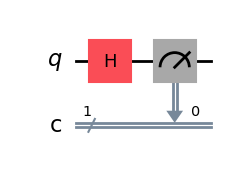

Measurement Counts: {'1': 498, '0': 526}


In [5]:
# Add a measurement to the circuit
qc_measure = QuantumCircuit(1, 1)

qc_measure.h(0)
qc_measure.measure(0, 0)

# Display the measurement circuit
display(qc_measure.draw("mpl"))

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

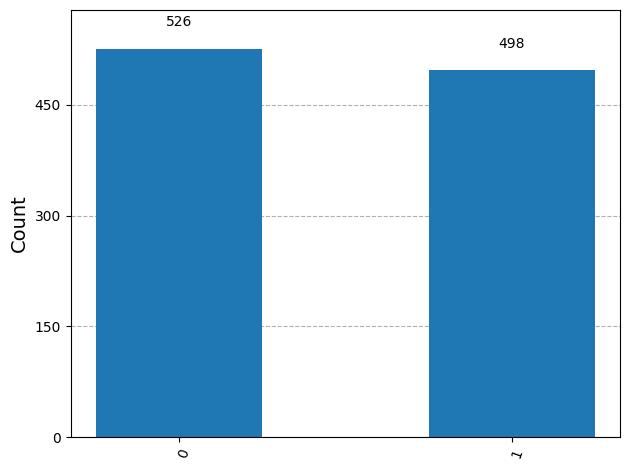

Probability of |0>: 0.513671875
Probability of |1>: 0.486328125


In [6]:
# Display the measurement histogram
display(plot_histogram(counts))

# Calculate the measured probabilities
total = sum(counts.values())

print("Probability of |0>:", counts.get("0", 0) / total)
print("Probability of |1>:", counts.get("1", 0) / total)